# EM алгоритм. Модель гауссовской смеси.

**ИППИ РАН · Байесовские методы машинного обучения · осень 2026**

Как разбить объекты на группы, если принадлежность к группе неизвестна?
Сначала введём скрытый номер компоненты и выведем EM для гауссовской смеси.
Затем реализуем его, проверим на простых данных и перейдём к основной задаче:
**каждый объект — целое распределение, представленное гистограммой с $B$ бинами**.
Нужно предложить признаки, геометрию или вероятностную модель, позволяющие
сгруппировать распределения по форме.

Потребуются формула Байеса, математическое ожидание, нормальное распределение,
производные и операции с массивами NumPy. ELBO из прошлого семинара пригодится
для понимания EM; нейросети нужны только в необязательном приложении.

**Маршрут на 120 минут:** модель и ELBO — 20; задания 1–2 и игрушечные
примеры — 35; задание 3 — 15; основная задача и обсуждение — 50.
Приложения про транспорт, выбор $K$ и VAE можно оставить на самостоятельную работу.

**Версия: решения и выполненные эксперименты.**


## Подготовка

Python 3.9+; основные зависимости: `numpy scipy matplotlib scikit-learn ipython`.
Для приложения VAE нужен `torch`. Все данные генерируются локально;
скачивание датасетов и GPU не требуются. Запускайте ячейки по порядку.

В заданиях реализуйте функции с указанными формами массивов. Проверки пропускают
только `NotImplementedError`: после заполнения функции повторно выполните её
ячейку, проверку и зависимые эксперименты. Остальные ошибки не скрываются.
Истинные метки синтетических данных используются только в заключительном аудите.


In [1]:
import sys
import numpy as np
import scipy
import sklearn
import matplotlib.pyplot as plt
from scipy.special import logsumexp, gammaln
from scipy.stats import norm
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from IPython.display import display, Markdown

RUN_VAE = True  # В студенческой версии приложение по умолчанию отключено.
SEED = 2026
completed = set()
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True,
                     'grid.alpha': .2, 'font.size': 10})

def check(name, test):
    completed.discard(name)
    try:
        test()
    except NotImplementedError:
        print(f'{name}: заполните реализацию и повторите эту проверку.')
    else:
        completed.add(name)
        print(f'{name}: проверки пройдены.')

def ready(*names):
    missing = set(names) - completed
    if missing:
        print('Сначала завершите: ' + ', '.join(sorted(missing)))
    return not missing

def table(headers, rows):
    fmt = lambda v: f'{v:.4f}' if isinstance(v, (float, np.floating)) else str(v)
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(fmt, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

def plot_histogram(ax, values, edges, fill=False, **kwargs):
    """Piecewise-constant density; compatible with Matplotlib 3.3+."""
    heights = np.r_[values, values[-1]]
    if fill:
        return ax.fill_between(edges, heights, step='post', **kwargs)
    return ax.step(edges, heights, where='post', **kwargs)

print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| SciPy', scipy.__version__, '| scikit-learn', sklearn.__version__)


Python 3.9.7 | NumPy 1.19.5 | SciPy 1.10.1 | scikit-learn 0.24.2


## 1. Скрытая компонента и наблюдаемое правдоподобие

Пусть $x_i\in\mathbb R^d$, $z_i\in\{1,\ldots,K\}$ и
$$p(z_i=k)=\pi_k,\qquad p(x_i\mid z_i=k)=\mathcal N(x_i;\mu_k,\Sigma_k),
\qquad \pi_k>0,\quad \sum_k\pi_k=1.$$
Маргинальная плотность и логарифм правдоподобия равны
$$p_\theta(x_i)=\sum_k\pi_k\mathcal N(x_i;\mu_k,\Sigma_k),\qquad
\ell(\theta)=\sum_i\log\sum_k\pi_k\mathcal N(x_i;\mu_k,\Sigma_k).$$
Логарифм суммы мешает раздельно оценить компоненты. Если бы $z_i$ были известны,
каждую гауссиану можно было бы обучить на своей группе. EM заменяет неизвестные
индикаторы принадлежности **мягкими весами**, а не единственной догадкой о метке.

**Обсудите:** что означает $\pi_k$? Почему $K$ компонент не обязательно дают
$K$ мод плотности? Изменится ли $p_\theta(x)$ при перестановке номеров компонент?


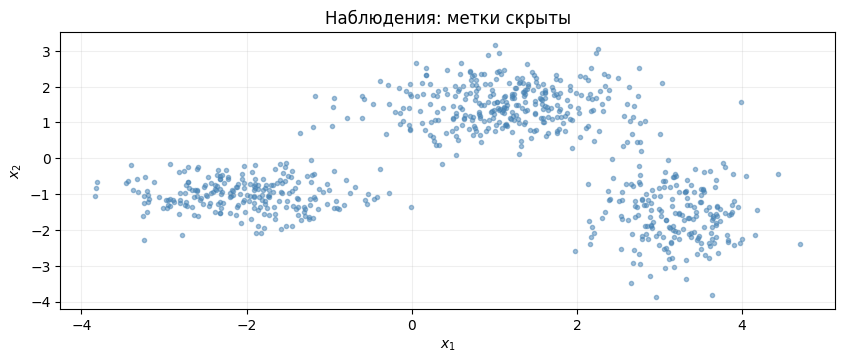

In [2]:
def make_toy(seed=SEED, n=750, rotated=False):
    rng = np.random.default_rng(seed)
    weights = np.array([.35, .4, .25])
    means = np.array([[-2., -1.], [1.2, 1.5], [3.2, -1.5]])
    covs = np.array([[[.5, 0], [0, .18]], [[.7, 0], [0, .35]],
                     [[.24, 0], [0, .65]]])
    if rotated:
        means = np.array([[-1.8, 0], [1.8, 0], [0, 2.8]])
        covs = np.array([[[1.2, 1.03], [1.03, 1.2]],
                         [[1.2, -1.03], [-1.03, 1.2]], [[.4, 0], [0, .4]]])
    labels = rng.choice(3, n, p=weights)
    X = np.vstack([rng.multivariate_normal(means[k], covs[k]) for k in labels])
    return X, labels

X_toy, toy_truth = make_toy()
plt.scatter(*X_toy.T, s=9, alpha=.5, color='steelblue')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title('Наблюдения: метки скрыты')
plt.show()


## 2. EM как покоординатный подъём ELBO

Для любых распределений $q_i(k)$ на компонентах введём
$$\mathcal F(q,\theta)=\sum_{i,k}q_i(k)
   [\log\pi_k+\log p_\theta(x_i\mid k)-\log q_i(k)].$$
Из формулы Байеса следует точное тождество
$$\ell(\theta)=\mathcal F(q,\theta)+
\sum_i D_{\rm KL}(q_i\|p_\theta(z_i\mid x_i)).$$
Здесь $0\log0=0$; KL неотрицательна. Поэтому $\mathcal F$ — нижняя граница.

**E-шаг:** при фиксированном $\theta^{(t)}$ выбрать
$q_i(k)=r_{ik}=p_{\theta^{(t)}}(z_i=k\mid x_i)$; зазор становится нулевым.
**M-шаг:** при фиксированных $r$ максимизировать
$Q(\theta)=\sum_{i,k}r_{ik}\log p_\theta(x_i,z_i=k)$.
Энтропия $q$ от новых параметров не зависит.

В результате точных шагов $\ell(\theta^{(t+1)})\geq\ell(\theta^{(t)})$.
Это не гарантия глобального максимума. Совпадение границы с правдоподобием
происходит **после E-шага для текущих параметров**, а не для любых $q,\theta$.

В VAE вместо точного постериора используется ограниченное семейство
$q_\phi(z\mid x)$ и градиентная оптимизация. Для конечной смеси сумма по $k$
вычисляется точно; сэмплировать дискретную метку для E-шага не требуется.

**На доске:** выведите тождество, раскрыв KL. Докажите цепочку
$\ell(\theta^{(t+1)})\geq\mathcal F(q^{(t)},\theta^{(t+1)})
\geq\mathcal F(q^{(t)},\theta^{(t)})=\ell(\theta^{(t)})$.


## Задание 1. Логарифмы плотностей и E-шаг · 15 минут

В реализации используем диагональные ковариации
$\Sigma_k=\operatorname{diag}(v_{k1},\ldots,v_{kd})$:
$$\log\mathcal N(x_i;\mu_k,\Sigma_k)
=-\frac12\sum_{j=1}^d\left[\log(2\pi v_{kj})+
                   \frac{(x_{ij}-\mu_{kj})^2}{v_{kj}}\right].$$
Пусть $a_{ik}=\log\pi_k+\log\mathcal N(x_i;\mu_k,\Sigma_k)$. Тогда
$$s_i=\operatorname{logsumexp}_k a_{ik},\qquad
r_{ik}=\exp(a_{ik}-s_i),\qquad \ell=\sum_i s_i.$$

Реализуйте `diag_logpdf` и `e_step`. Не перемножайте плотности и не вычисляйте
`log(exp(a).sum())`: в хвостах это приводит к потере значимости или underflow.
Функции получают конечные массивы; веса положительны, дисперсии строго положительны.


In [3]:
def diag_logpdf(X, means, variances):
    """X: (N,d), means/variances: (K,d) -> log densities: (N,K)."""
    diff = X[:, None, :] - means[None, :, :]
    return -.5 * (np.log(2*np.pi*variances)[None, :, :]
                  + diff**2 / variances[None, :, :]).sum(axis=2)

def e_step(X, weights, means, variances):
    """Return responsibilities (N,K), observed log likelihood (scalar)."""
    scores = diag_logpdf(X, means, variances) + np.log(weights)[None, :]
    normalizer = logsumexp(scores, axis=1)
    return np.exp(scores-normalizer[:, None]), normalizer.sum()


In [4]:
def test_e_step():
    X = np.array([[0.], [1.], [10000.]])
    means = np.array([[0.], [2.]])
    v = np.ones((2, 1))
    logp = diag_logpdf(X, means, v)
    np.testing.assert_allclose(logp[:, 0], norm.logpdf(X[:, 0]))
    R, ll = e_step(X, np.array([.5, .5]), means, v)
    np.testing.assert_allclose(R.sum(1), 1.)
    np.testing.assert_allclose(R[1], [.5, .5])
    np.testing.assert_allclose(R[0, 0], 1/(1+np.exp(-2)))
    assert np.isfinite(ll) and np.isfinite(R).all()
    perm, ll_perm = e_step(X, np.array([.5, .5]), means[::-1], v[::-1])
    np.testing.assert_allclose(perm[:, ::-1], R)
    np.testing.assert_allclose(ll_perm, ll)

check('E-шаг', test_e_step)


E-шаг: проверки пройдены.


## 3. M-шаг: взвешенные достаточные статистики

Обозначим $N_k=\sum_i r_{ik}$. Максимизация $Q$ при $\sum_k\pi_k=1$ даёт
$$\pi_k^{\rm new}=N_k/N,\qquad
\mu_k^{\rm new}=\frac{\sum_i r_{ik}x_i}{N_k},$$
$$\Sigma_k^{\rm new}=\frac1{N_k}\sum_i r_{ik}
 (x_i-\mu_k^{\rm new})(x_i-\mu_k^{\rm new})^\top.$$
Это оценка максимального правдоподобия: деление на $N_k$, а не $N_k-1$.
Для диагональной модели оставляем только покоординатные дисперсии.

Без ограничений правдоподобие GMM может не иметь конечного максимума:
одна компонента стягивается в отдельную точку. В нашем коде фиксируем
$v_{kj}\geq v_{\min}>0$. Тогда **точный ограниченный M-шаг** имеет вид
$$v_{kj}^{\rm new}=\max\left\{v_{\min},
  N_k^{-1}\sum_i r_{ik}(x_{ij}-\mu_{kj}^{\rm new})^2\right\}.$$
Добавление `eps` к каждой дисперсии — другая операция и само по себе не
обеспечивает тот же точный ограниченный M-шаг.


## Задание 2. M-шаг и цикл EM · 20 минут

1. Реализуйте `m_step_diag`; центруйте по **новому** среднему.
2. Реализуйте `fit_diag_gmm`. Для каждого запуска: инициализация → E-шаг →
   M-шаг → E-шаг → запись нового правдоподобия. История должна включать
   значение для начальных параметров и финальной модели.
3. Останавливайтесь при улучшении не больше `tol * (1 + abs(previous_ll))`.
   Из `n_init` независимых запусков оставляйте лучший по обучающему правдоподобию.
4. Если $N_k<10^{-10}$, прекращайте этот запуск. Переинициализация компоненты
   допустима как эвристика, но нарушает простое доказательство монотонности.

Инициализацию K-means мы предоставляем. Разделите ответственность за случайные
числа: один генератор и отдельный seed для каждого старта.


In [5]:
def m_step_diag(X, R, var_floor=1e-4):
    """X: (N,d), R: (N,K). Return weights (K,), means/variances (K,d)."""
    nk = R.sum(axis=0)
    if np.any(nk < 1e-10):
        raise FloatingPointError('Пустая компонента: перезапустите EM.')
    means = R.T @ X / nk[:, None]
    delta = X[:, None, :] - means[None, :, :]
    variances = np.einsum('nk,nkd->kd', R, delta**2) / nk[:, None]
    return nk / len(X), means, np.maximum(variances, var_floor)

def initialize_diag(X, K, seed, var_floor):
    labels = KMeans(n_clusters=K, n_init=1, random_state=seed).fit_predict(X)
    R = .98*np.eye(K)[labels] + .02/K
    return m_step_diag(X, R, var_floor)

def fit_diag_gmm(X, K, seed=0, n_init=5, max_iter=150, tol=1e-7, var_floor=1e-4):
    """Return dict: weights, means, variances, history, converged, n_iter."""
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        try:
            w, mu, v = initialize_diag(X, K, int(rng.integers(2**30)), var_floor)
            R, ll = e_step(X, w, mu, v)
            history, converged = [ll], False
            for step in range(max_iter):
                w, mu, v = m_step_diag(X, R, var_floor)
                R, ll = e_step(X, w, mu, v)
                gain = ll-history[-1]
                if gain < -1e-7*(1+abs(history[-1])):
                    raise RuntimeError('Правдоподобие уменьшилось: проверьте шаги.')
                history.append(ll)
                if gain <= tol*(1+abs(history[-2])):
                    converged = True
                    break
            model = dict(weights=w, means=mu, variances=v,
                         history=np.array(history), converged=converged,
                         n_iter=len(history)-1)
            if best is None or ll > best['history'][-1]:
                best = model
        except FloatingPointError:
            continue
    if best is None:
        raise RuntimeError('Все запуски потеряли компоненту. Измените seed или K.')
    return best

def predict_diag(model, X):
    return e_step(X, model['weights'], model['means'], model['variances'])[0]


In [6]:
def test_em():
    X = np.array([[0.], [2.], [8.], [10.]])
    R = np.array([[1., 0], [1., 0], [0, 1.], [0, 1.]])
    w, mu, v = m_step_diag(X, R)
    np.testing.assert_allclose(w, [.5, .5])
    np.testing.assert_allclose(mu[:, 0], [1., 9.])
    np.testing.assert_allclose(v[:, 0], [1., 1.])
    _, _, vf = m_step_diag(np.zeros((4, 1)), R, var_floor=.03)
    np.testing.assert_allclose(vf, .03)
    model = fit_diag_gmm(X_toy[:300], 3, seed=11, n_init=2)
    assert len(model['history']) >= 2
    assert np.min(np.diff(model['history'])) >= -1e-6
    np.testing.assert_allclose(predict_diag(model, X_toy[:10]).sum(1), 1.)
    final_ll = e_step(X_toy[:300], model['weights'], model['means'], model['variances'])[1]
    np.testing.assert_allclose(final_ll, model['history'][-1])

if ready('E-шаг'):
    check('EM', test_em)


EM: проверки пройдены.


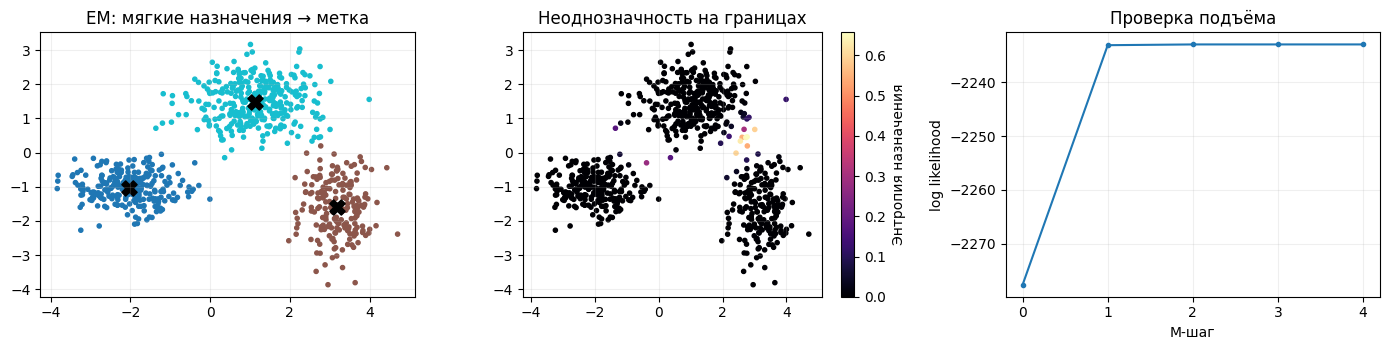

Сходимость: True | M-шагов: 4


| Модель | Средний log p(x) на обучении |
| --- | --- |
| Наша диагональная GMM | -2.9772 |
| sklearn, diag | -2.9772 |

In [7]:
if ready('E-шаг', 'EM'):
    toy_model = fit_diag_gmm(X_toy, 3, seed=SEED)
    toy_R = predict_diag(toy_model, X_toy)
    entropy = -(toy_R * np.log(np.maximum(toy_R, 1e-300))).sum(1)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
    axes[0].scatter(*X_toy.T, c=toy_R.argmax(1), s=9, cmap='tab10')
    axes[0].scatter(*toy_model['means'].T, marker='X', s=120, c='black')
    axes[0].set_title('EM: мягкие назначения → метка')
    image = axes[1].scatter(*X_toy.T, c=entropy, s=9, cmap='magma')
    fig.colorbar(image, ax=axes[1], label='Энтропия назначения')
    axes[1].set_title('Неоднозначность на границах')
    axes[2].plot(toy_model['history'], marker='.')
    axes[2].set(xlabel='M-шаг', ylabel='log likelihood', title='Проверка подъёма')
    plt.tight_layout(); plt.show()
    print('Сходимость:', toy_model['converged'], '| M-шагов:', toy_model['n_iter'])
    library = GaussianMixture(3, covariance_type='diag', n_init=5,
                              reg_covar=1e-6, random_state=SEED).fit(X_toy)
    table(['Модель', 'Средний log p(x) на обучении'], [
        ['Наша диагональная GMM', toy_model['history'][-1]/len(X_toy)],
        ['sklearn, diag', library.score(X_toy)]])


**Вопросы к эксперименту.** Где назначения наиболее неопределённы? Является ли
энтропия $r_i$ неопределённостью параметров? Почему наша модель и `sklearn`
могут дать близкие, но разные результаты? Сравнивайте плотности и назначения
с учётом перестановки компонент, а не по номеру кластера.

При фиксированной общей сферической ковариации $\sigma^2I$ и равных весах
$\sigma\to0$ делает назначения ближайшему среднему жёсткими. M-шаг средних
тогда совпадает с обновлением K-means. Обычный K-means не оценивает
произвольные ковариации GMM.

### Когда диагональных ковариаций недостаточно

Следующий пример заранее фиксирован. Обучим диагональную и полную GMM на
одних наблюдениях; сравним плотность на независимых объектах в **одном
и том же исходном пространстве**. `reg_covar` в sklearn добавляет регуляризацию
к диагонали: это не наш оператор `max`.


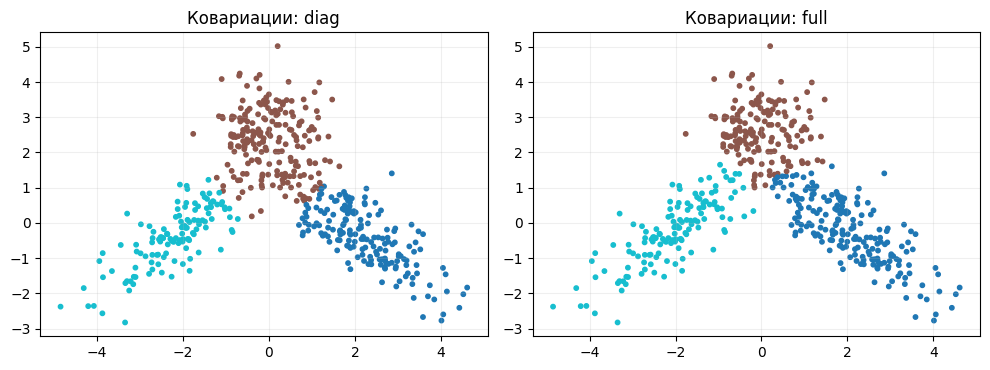

| Ковариации | Средний test log p(x) | Сходимость |
| --- | --- | --- |
| diag | -3.4660 | True |
| full | -3.1948 | True |

In [8]:
X_rot, _ = make_toy(seed=SEED+1, n=1400, rotated=True)
rot_train, rot_test = X_rot[:900], X_rot[900:]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
rot_rows = []
for ax, kind in zip(axes, ['diag', 'full']):
    gm = GaussianMixture(3, covariance_type=kind, n_init=6,
                         reg_covar=1e-4, random_state=42).fit(rot_train)
    ax.scatter(*rot_test.T, c=gm.predict(rot_test), cmap='tab10', s=10)
    ax.set_title('Ковариации: ' + kind)
    rot_rows.append([kind, gm.score(rot_test), gm.converged_])
plt.tight_layout(); plt.show()
table(['Ковариации', 'Средний test log p(x)', 'Сходимость'], rot_rows)


## Задание 3. EM для целых гистограмм · 15 минут

Для разминки заменим гауссовское условное распределение на мультиномиальное.
Каждый объект $c_i=(c_{i1},\ldots,c_{iB})$ — целочисленные счётчики,
$n_i=\sum_b c_{ib}>0$. У **всего объекта** один номер компоненты $z_i$:
$$z_i\sim\operatorname{Cat}(\pi),\qquad
c_i\mid z_i=k,n_i\sim\operatorname{Multinomial}(n_i,\theta_k),
\quad \sum_b\theta_{kb}=1.$$
Здесь $\theta_{kb}$ — вероятность бина $b$ для шаблона $k$.
Это не кластеризация отдельных бинов и не GMM для скалярных значений внутри
одной гистограммы. В модели $n_i$ считается заданным.

Мультиномиальный коэффициент $n_i!/\prod_b c_{ib}!$ не зависит от $k$:
$$a_{ik}=\log\pi_k+\sum_b c_{ib}\log\theta_{kb},\quad
r_{ik}=\exp(a_{ik}-\operatorname{logsumexp}_l a_{il}).$$
Для ML M-шаг равен
$$\pi_k=N_k/N,\qquad
\theta_{kb}=\frac{\sum_i r_{ik}c_{ib}}{\sum_i r_{ik}n_i}.$$

Чтобы исключить нулевые шаблонные вероятности, возьмём независимые симметричные
априорные распределения $\theta_k\sim\operatorname{Dirichlet}(\alpha,\ldots,\alpha)$,
$\alpha=1.05$. **MAP M-шаг** добавляет $\alpha-1$ к каждому взвешенному счётчику:
$$\theta_{kb}=\frac{\sum_i r_{ik}c_{ib}+\alpha-1}
 {\sum_i r_{ik}n_i+B(\alpha-1)}.$$
При $\alpha=1$ получаем ML; используйте $\alpha>1$ в коде.
Монотонно растёт логарифм апостериорной плотности, а не обязательно чистое
правдоподобие. Добавка $\alpha$, в отличие от $\alpha-1$, соответствовала бы
другой оценке. Реализуйте E- и M-шаги; цикл EM предоставлен.


In [9]:
def multinomial_e_step(C, weights, templates):
    """C (N,B), weights (K,), templates (K,B), all templates > 0.
    Return R (N,K), LL without multinomial coefficients (scalar).
    """
    scores = np.log(weights)[None, :] + C @ np.log(templates).T
    lse = logsumexp(scores, axis=1)
    return np.exp(scores-lse[:, None]), lse.sum()

def multinomial_m_step(C, R, alpha=1.05):
    """MAP update; alpha > 1. Return weights (K,), templates (K,B)."""
    nk = R.sum(0)
    if np.any(nk < 1e-10):
        raise FloatingPointError('Пустая компонента.')
    counts = R.T @ C + alpha-1
    return nk/len(C), counts/counts.sum(1, keepdims=True)


In [10]:
def fit_multinomial(C, K, seed=0, n_init=6, max_iter=180, tol=1e-7, alpha=1.05):
    if alpha <= 1:
        raise ValueError('В этой учебной реализации требуется alpha > 1.')
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        labels = KMeans(K, n_init=1, random_state=int(rng.integers(2**30))).fit_predict(
            np.sqrt(C/C.sum(1, keepdims=True)))
        R = .98*np.eye(K)[labels] + .02/K
        history, converged = [], False
        try:
            for step in range(max_iter):
                w, theta = multinomial_m_step(C, R, alpha)
                R, ll = multinomial_e_step(C, w, theta)
                objective = ll + (alpha-1)*np.log(theta).sum()
                history.append(objective)
                if len(history) > 1:
                    gain = history[-1]-history[-2]
                    if gain < -1e-7*(1+abs(history[-2])):
                        raise RuntimeError('MAP-цель уменьшилась.')
                    if gain <= tol*(1+abs(history[-2])):
                        converged = True
                        break
            model = dict(weights=w, templates=theta, history=np.array(history),
                         converged=converged)
            if best is None or objective > best['history'][-1]:
                best = model
        except FloatingPointError:
            continue
    if best is None:
        raise RuntimeError('Все запуски потеряли компоненту.')
    return best

def predict_multinomial(model, C):
    return multinomial_e_step(C, model['weights'], model['templates'])[0]

def multinomial_logpmf(model, C):
    coefficients = gammaln(C.sum(1)+1)-gammaln(C+1).sum(1)
    scores = np.log(model['weights'])[None, :] + C@np.log(model['templates']).T
    return coefficients + logsumexp(scores, axis=1)

def test_multinomial():
    C = np.array([[8, 2, 0], [2, 8, 0], [4, 1, 0], [1, 4, 0]])
    R = np.array([[1., 0], [0, 1.], [1., 0], [0, 1.]])
    w, theta = multinomial_m_step(C, R, alpha=2.)
    np.testing.assert_allclose(w, [.5, .5])
    np.testing.assert_allclose(theta[0], [13/18, 4/18, 1/18])
    np.testing.assert_allclose(theta.sum(1), 1.)
    R1, _ = multinomial_e_step(np.array([[9, 1, 0]]), w, theta)
    R2, _ = multinomial_e_step(np.array([[90, 10, 0]]), w, theta)
    assert R2[0, 0] > R1[0, 0] > .5
    assert np.isfinite(theta).all() and (theta > 0).all()
    model = fit_multinomial(C, 2, n_init=2)
    assert np.all(np.diff(model['history']) >= -1e-6)
    np.testing.assert_allclose(predict_multinomial(model, C).sum(1), 1.)

check('Мультиномиальная смесь', test_multinomial)


Мультиномиальная смесь: проверки пройдены.


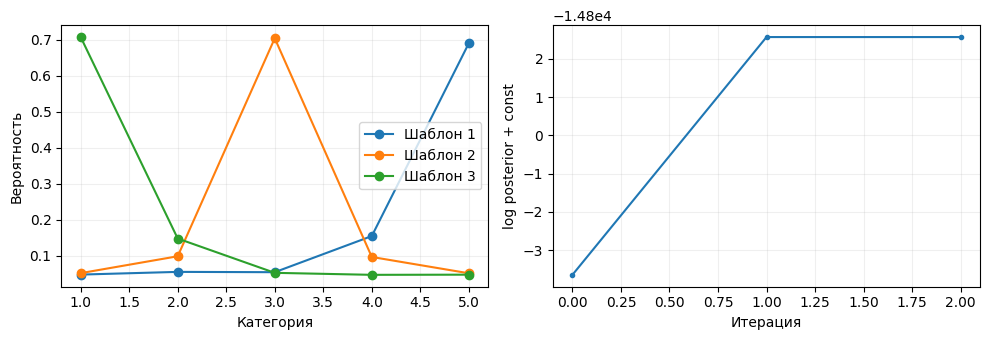

In [11]:
# Простой пример до основной задачи: три шаблона на пяти категориях.
mini_rng = np.random.default_rng(31)
mini_templates = np.array([[.7, .15, .05, .05, .05],
                           [.05, .1, .7, .1, .05], [.05, .05, .05, .15, .7]])
mini_ids = mini_rng.choice(3, 240)
mini_C = np.array([mini_rng.multinomial(int(mini_rng.integers(20, 100)),
                                       mini_templates[k]) for k in mini_ids])
if ready('Мультиномиальная смесь'):
    mini_model = fit_multinomial(mini_C, 3, seed=32)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for k, theta in enumerate(mini_model['templates']):
        axes[0].plot(np.arange(1, 6), theta, marker='o', label=f'Шаблон {k+1}')
    axes[0].set(xlabel='Категория', ylabel='Вероятность'); axes[0].legend()
    axes[1].plot(mini_model['history'], marker='.')
    axes[1].set(xlabel='Итерация', ylabel='log posterior + const')
    plt.tight_layout(); plt.show()


**Проверьте смысл модели.** Две гистограммы с одинаковыми долями, но
$n=10$ и $n=1000$ несут разное количество информации. Почему E-шаг учитывает
это различие? Что изменится, если передать в него доли вместо счётчиков?
Можно ли восстановить $n_i$, если сохранены только высоты нормированной плотности?


## 4. Основная задача: кластеризация распределений · 50 минут

Объект $i$ — распределение скалярной величины $T$, представленное гистограммой.
Для всех объектов известны общие границы $a_0<\cdots<a_B$;
$\Delta_b=a_b-a_{b-1}$. Различайте:

| Величина | Обозначение | Нормировка |
|---|---|---|
| Счётчик наблюдений в бине | $c_{ib}$ | $\sum_b c_{ib}=n_i$ |
| Вероятностная масса бина | $p_{ib}=c_{ib}/n_i$ | $\sum_b p_{ib}=1$ |
| Высота плотности | $h_{ib}=p_{ib}/\Delta_b$ | $\sum_b h_{ib}\Delta_b=1$ |

Матрицы имеют форму $(N,B)$: **строка — объект для кластеризации**.
Для неравных ширин сумма высот плотности не равна единице. Взятые в разных
сетках гистограммы сначала нужно привести к общей сетке с сохранением масс.
Ни перестановка бинов, ни стандартизация каждого бина по отдельности не
сохраняют исходную геометрию распределений автоматически.

### До кода: сформулируйте собственный подход

В течение пяти минут обсудите в паре и запишите:

1. Что такое «похожие распределения»: совпадают среднее и масштаб,
   форма, моды или положение массы вдоль оси? Должен ли небольшой сдвиг
   менять кластер? Нужно ли удалять сдвиг и масштаб?
2. Какой объект подать в GMM? Какие свойства будут потеряны?
3. Можно ли использовать счётчики и моделировать шум оценки гистограммы?
4. Как сравнить качество без истинных меток и как показать смысл кластеров?

**Предложите минимум два подхода до чтения подсказок ниже.** Один должен
использовать GMM; второй может менять признаки, расстояние или модель объекта.
Выбор признаков, $K$ и параметров зафиксируйте до заключительного аудита.


### Протокол эксперимента

Даны 720 независимых объектов, $B=64$ и разные размеры выборок $n_i$ от 60
до 600. Случайный сдвиг и масштаб создают внутрикластерную вариативность.
В учебной постановке число семейств известно: **$K=4$**. Это дополнительное
условие задачи, а не результат просмотра истинных меток.

Сначала случайно разделим **объекты** на 480 обучающих и 240 отложенных.
PCA, стандартизацию, GMM, шаблоны и медоиды оцениваем только на обучении.
Для назначения новых объектов используем уже обученную модель. Не разделяем
бины и отдельные отсчёты одного объекта между обучением и тестом.

Метки семейства и истинные вероятности доступны только в функции
`simulation_audit`; не вызывайте её до фиксации методов. В реальной задаче
такой функции нет. Фиксированные seeds делают сравнение воспроизводимым,
но не гарантируют побитового совпадения между версиями библиотек.


Обучение: (480, 64) | тест: (240, 64) | n_i: 60 … 600


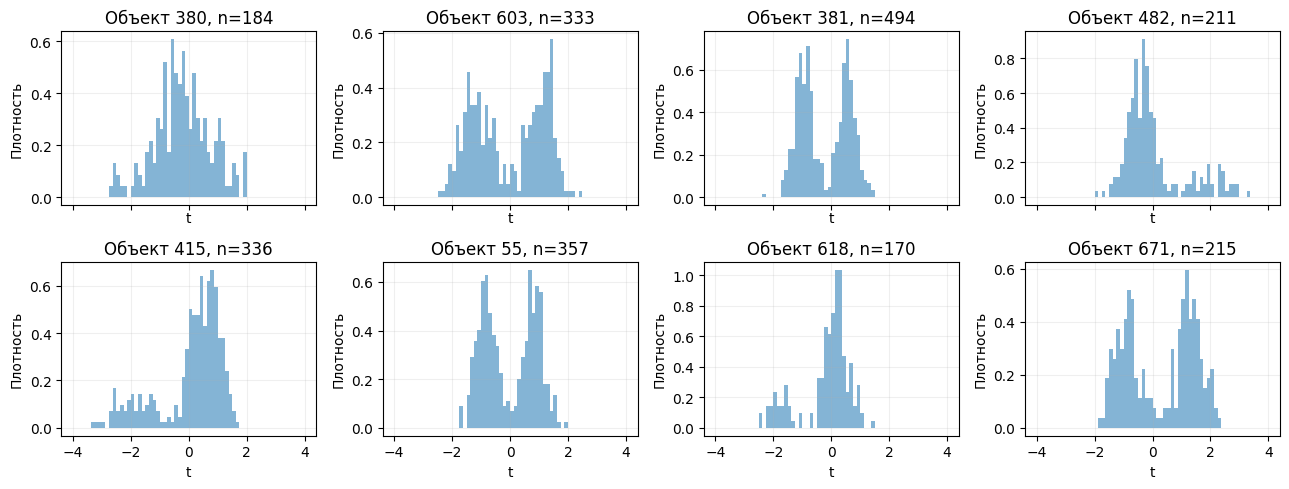

In [12]:
def generate_histograms(seed=SEED, n_objects=720, B=64):
    rng = np.random.default_rng(seed)
    edges = np.linspace(-4, 4, B+1)
    labels = np.arange(n_objects) % 4
    rng.shuffle(labels)
    sizes = np.rint(np.exp(rng.uniform(np.log(60), np.log(600), n_objects))).astype(int)
    true_masses = []
    for label in labels:
        if label == 0:
            w, loc, scale = [1.], np.array([0.]), np.array([1.])
        elif label == 1:
            s = np.sqrt(.85**2+.35**2)
            w, loc, scale = [.5, .5], np.array([-.85, .85])/s, np.array([.35, .35])/s
        else:
            s = np.sqrt(.8*(.45**2+.45**2)+.2*(1.8**2+.6**2))
            w, loc, scale = [.8, .2], np.array([-.45, 1.8])/s, np.array([.45, .6])/s
            if label == 3:
                loc = -loc
        shift, stretch = rng.normal(0, .18), np.exp(rng.normal(0, .1))
        cdf = norm.cdf((edges[:, None]-(shift+stretch*loc))/(stretch*scale)).dot(w)
        mass = np.diff(cdf)
        true_masses.append(mass/mass.sum())
    true_masses = np.array(true_masses)
    C = np.array([rng.multinomial(n, p) for n, p in zip(sizes, true_masses)])
    return C, edges, labels, true_masses

def make_seminar_data():
    C, edges, hidden_y, hidden_p = generate_histograms()
    # Это учебное сокрытие ответа, а не защита от намеренного чтения исходников.
    def simulation_audit():
        return hidden_y.copy(), hidden_p.copy()
    return C, edges, simulation_audit

C, edges, simulation_audit = make_seminar_data()
widths = np.diff(edges)
centers = (edges[:-1]+edges[1:])/2
n_obs = C.sum(1)
P = C/n_obs[:, None]
H = P/widths[None, :]
K = 4
ids = np.random.default_rng(42).permutation(len(C))
train_ids, test_ids = ids[:480], ids[480:]
C_train, C_test = C[train_ids], C[test_ids]
P_train, P_test = P[train_ids], P[test_ids]
assert C.shape == (720, 64) and np.all(C >= 0)
np.testing.assert_allclose(P.sum(1), 1.)
np.testing.assert_allclose((H*widths).sum(1), 1.)
# На неравномерной сетке складываются массы, а не высоты плотности.
demo_widths = np.diff([0., 1., 3.])
demo_density = np.array([.5, .25])
np.testing.assert_allclose(demo_density*demo_widths, [.5, .5])
print('Обучение:', C_train.shape, '| тест:', C_test.shape,
      '| n_i:', n_obs.min(), '…', n_obs.max())

fig, axes = plt.subplots(2, 4, figsize=(13, 5), sharex=True)
for ax, i in zip(axes.flat, train_ids[:8]):
    plot_histogram(ax, H[i], edges, fill=True, alpha=.55)
    ax.set_title(f'Объект {i}, n={n_obs[i]}')
    ax.set(xlabel='t', ylabel='Плотность')
plt.tight_layout(); plt.show()


### Задание 4. Спроектируйте и исследуйте метод

Реализуйте `fit_distribution_clustering` со следующим контрактом:
функция обучается только на `P_fit`, затем возвращает словарь с метками
`train_labels` и `test_labels`, а также **краткое описание** `description`.
Истинные метки, `simulation_audit` и тестовые ответы функция не использует.
Можно добавить поля с преобразованием и обученной моделью.

Сначала реализуйте GMM по выбранным вами признакам. Затем предложите
второй метод или другую осмысленную систему признаков. Сравните их с
предоставленным базовым вариантом «среднее + дисперсия». Покажите
представителей кластеров и устойчивость к трём инициализациям.

**Критерий выполнения:** воспроизводимый эксперимент, обоснование геометрии,
описание потерь информации, честная оценка и содержательная интерпретация.
Высокий ARI сам по себе не заменяет эти пункты.


In [13]:
def fit_distribution_clustering(P_fit, P_new, K, seed):
    """Fit only on P_fit. Return labels and a textual method description."""
    pca = PCA(n_components=8, svd_solver='full').fit(np.sqrt(P_fit))
    Z_fit, Z_new = pca.transform(np.sqrt(P_fit)), pca.transform(np.sqrt(P_new))
    model = GaussianMixture(K, covariance_type='full', n_init=6,
                            reg_covar=1e-4, random_state=seed).fit(Z_fit)
    return dict(train_labels=model.predict(Z_fit), test_labels=model.predict(Z_new),
                description='sqrt(массы) → PCA(8) → GMM(full)',
                pca=pca, model=model, train_embedding=Z_fit, test_embedding=Z_new)


In [14]:
def test_distribution_method():
    a = fit_distribution_clustering(P_train[:100], P_test[:11], K, 51)
    for key, n in [('train_labels', 100), ('test_labels', 11)]:
        labels = np.asarray(a[key])
        assert labels.shape == (n,) and np.issubdtype(labels.dtype, np.integer)
        assert np.all((0 <= labels) & (labels < K))
    assert isinstance(a['description'], str) and a['description']
    # Назначение фиксированного объекта не должно зависеть от соседей в тесте.
    b = fit_distribution_clustering(P_train[:100], P_test[3:4], K, 51)
    assert a['test_labels'][3] == b['test_labels'][0]

check('Метод для распределений', test_distribution_method)


Метод для распределений: проверки пройдены.


### Подсказки для обсуждения после собственного плана

**Признаки.** Среднее и дисперсия компактны, но не определяют форму.
Асимметрия и четвёртый момент сохраняют больше информации, хотя чувствительны
к редким отсчётам и хвостам. Прямые массы лежат на симплексе; полная ковариация
в $\mathbb R^B$ вырождена из-за $\sum_b p_b=1$. PCA с меньшей размерностью
или диагональные ковариации снимают часть численных трудностей, но меняют модель.

**Геометрия Хеллингера.** Для вероятностных масс
$$H^2(p,q)=\frac12\sum_b(\sqrt{p_b}-\sqrt{q_b})^2.$$
Поэтому евклидово расстояние между $\sqrt p$ соответствует Хеллингеру
с постоянным множителем. Нули допустимы. PCA без whitening сохраняет
основные направления разброса, но отбрасывание координат теряет часть расстояния.
GMM в PCA-пространстве — модель признаков, а не точная модель симплекса.

**Счётчики.** Мультиномиальная смесь из задания 3 моделирует конечную
точность гистограммы. Один шаблон на компоненту не описывает всю реальную
вариативность форм: при случайном сдвиге/масштабе это приближение.
Большое $n_i$ может давать излишнюю уверенность у неверно заданной модели.
Без известных $n_i$ подставлять произвольные счётчики не следует.

**Расположение бинов.** Хеллингер и обычные признаки масс сами по себе не
учитывают порядок бинов. Для распределений на прямой можно сравнивать CDF
и использовать транспортное расстояние; см. приложение A.


In [15]:
def histogram_moments(P, centers, n_features=2):
    mean = P @ centers
    delta = centers[None, :] - mean[:, None]
    variance = np.maximum((P*delta**2).sum(1), 1e-12)
    if n_features == 2:
        return np.c_[mean, variance]
    skew = (P*delta**3).sum(1)/variance**1.5
    kurtosis = (P*delta**4).sum(1)/variance**2
    return np.c_[mean, variance, skew, kurtosis]

def fit_moment_baseline(P_fit, P_new, seed=12, n_features=2):
    A = histogram_moments(P_fit, centers, n_features)
    B = histogram_moments(P_new, centers, n_features)
    scaler = StandardScaler().fit(A)
    gm = GaussianMixture(K, covariance_type='full', n_init=6, reg_covar=1e-4,
                         random_state=seed).fit(scaler.transform(A))
    return dict(train_labels=gm.predict(scaler.transform(A)),
                test_labels=gm.predict(scaler.transform(B)), model=gm)

methods = {'Среднее + дисперсия': fit_moment_baseline(P_train, P_test)}
if ready('Метод для распределений'):
    student_method = fit_distribution_clustering(P_train, P_test, K, 12)
    methods['Предложенный GMM'] = student_method
    print(student_method['description'])
if ready('Мультиномиальная смесь'):
    count_model = fit_multinomial(C_train, K, seed=8)
    methods['EM: мультиномиальная смесь'] = dict(
        train_labels=predict_multinomial(count_model, C_train).argmax(1),
        test_labels=predict_multinomial(count_model, C_test).argmax(1), model=count_model)
    print('Счётчики: сходимость', count_model['converged'],
          '| MAP-итераций', len(count_model['history']))


sqrt(массы) → PCA(8) → GMM(full)
Счётчики: сходимость True | MAP-итераций 3


### Представители и устойчивость без истинных меток

Нарисуйте среднюю **массу**, переведённую в плотность, для каждого предсказанного
кластера и несколько отдельных объектов. Рядом укажите число объектов и
распределение $n_i$: не возникла ли группа исключительно из-за шумности?
Среднее по объектам и шаблон мультиномиальной смеси различаются: второй
взвешивает информацию о бинах по количеству отсчётов и мягким назначениям.

Для устойчивости используйте ARI между двумя предсказанными разбиениями
одних и тех же отложенных объектов. Здесь ARI сравнивает **две модели**,
истинные метки ему не нужны. Устойчивое разбиение ещё не обязательно полезно.


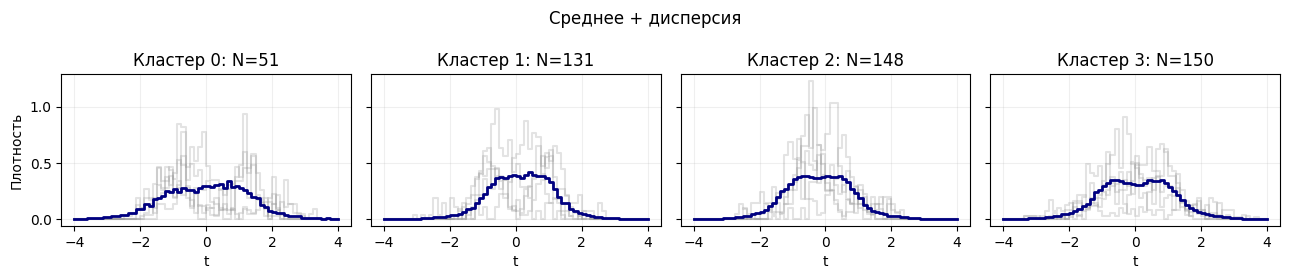

| Кластер | Число объектов | Медиана n_i |
| --- | --- | --- |
| 0 | 51 | 176.0000 |
| 1 | 131 | 233.0000 |
| 2 | 148 | 201.5000 |
| 3 | 150 | 233.5000 |

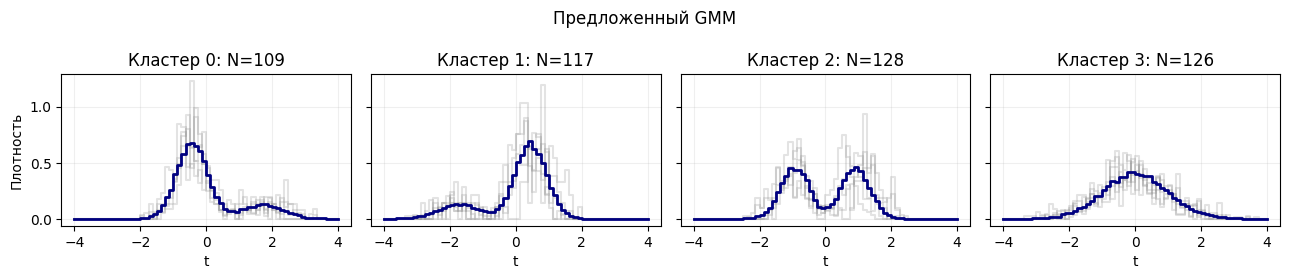

| Кластер | Число объектов | Медиана n_i |
| --- | --- | --- |
| 0 | 109 | 200.0000 |
| 1 | 117 | 219.0000 |
| 2 | 128 | 238.0000 |
| 3 | 126 | 232.0000 |

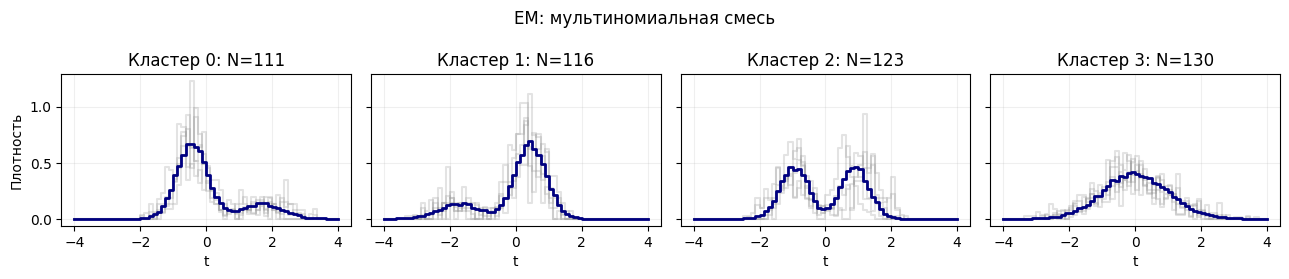

| Кластер | Число объектов | Медиана n_i |
| --- | --- | --- |
| 0 | 111 | 200.0000 |
| 1 | 116 | 221.0000 |
| 2 | 123 | 233.0000 |
| 3 | 130 | 233.0000 |

| Seed A | Seed B | ARI между разбиениями |
| --- | --- | --- |
| 11 | 22 | 1.0000 |
| 11 | 33 | 1.0000 |
| 22 | 33 | 1.0000 |

In [16]:
def plot_clusters(P_fit, labels, title):
    fig, axes = plt.subplots(1, K, figsize=(13, 2.8), sharey=True)
    for k, ax in enumerate(axes):
        ids_k = np.flatnonzero(labels == k)
        for j in ids_k[:5]:
            plot_histogram(ax, P_fit[j]/widths, edges, color='grey', alpha=.22)
        if len(ids_k):
            plot_histogram(ax, P_fit[ids_k].mean(0)/widths, edges, color='navy', linewidth=2)
        ax.set_title(f'Кластер {k}: N={len(ids_k)}')
        ax.set_xlabel('t')
    axes[0].set_ylabel('Плотность')
    fig.suptitle(title); plt.tight_layout(); plt.show()

for name, result in methods.items():
    plot_clusters(P_train, result['train_labels'], name)
    table(['Кластер', 'Число объектов', 'Медиана n_i'], [
        [k, int((result['train_labels'] == k).sum()),
         float(np.median(n_obs[train_ids][result['train_labels'] == k]))
         if np.any(result['train_labels'] == k) else '—'] for k in range(K)])

if ready('Метод для распределений'):
    repeats = [fit_distribution_clustering(P_train, P_test, K, seed)['test_labels']
               for seed in [11, 22, 33]]
    table(['Seed A', 'Seed B', 'ARI между разбиениями'], [
        [a, b, adjusted_rand_score(repeats[i], repeats[j])]
        for i, a in enumerate([11, 22, 33]) for j, b in enumerate([11, 22, 33]) if i < j])


### Дополнительный эксперимент студента

Добавьте в `methods` собственный второй метод в том же формате. Например,
четыре момента, другая размерность признаков, сглаженные гистограммы с
обоснованным выбором масштаба или расстояние Васерштейна.
Параметры выбирайте на внутреннем разделении обучающих объектов,
по устойчивости и интерпретации, не по тестовым меткам.

Зафиксируйте ожидаемый эффект **до** запуска: где ваш метод должен помочь
и какую информацию он игнорирует? Затем проведите один контрольный эксперимент
(прореживание до меньших $n_i$ либо новая независимая симуляция с иной сеткой
$B$ или большим разбросом сдвигов). Для другой сетки нужно переобучить преобразование.
Нельзя складывать соседние бины как высоты плотности: складываются массы/счётчики.


In [17]:
# Пример второго варианта: четыре момента; все параметры заданы заранее.
methods['Четыре момента'] = fit_moment_baseline(P_train, P_test, n_features=4)


**Разбор выбранного подхода.** В качестве сходства используем форму
распределения на исходной оси; заранее не удаляем сдвиг и масштаб.
Преобразование $\sqrt p$ учитывает различия масс в геометрии Хеллингера,
PCA(8) уменьшает размерность, полная GMM описывает эллиптический разброс
признаков. Число координат и регуляризация заданы до открытия ответов.
Восемь координат сохраняют только часть информации; разные распределения
могут иметь одинаковую проекцию, а GMM не моделирует ограничения симплекса.

Второй вариант — GMM по четырём моментам. Он сохраняет асимметрию и
характер хвостов при малой размерности, но не определяет распределение
однозначно. Для контроля используем прореживание до 30 отсчётов: при таком
шуме признаки формы менее точны. Мультиномиальная смесь моделирует сами
счётчики и поэтому представляет отдельную, вероятностно мотивированную
альтернативу. Её ограничение — единственная шаблонная форма на кластер.

Интерпретация строится по средним и отдельным гистограммам, размерам групп
и $n_i$. Устойчивость к seed измеряется до открытия истинных меток;
окончательные числа и обсуждение приведены в аудите ниже.


## 5. Заключительный аудит симуляции

Вызовите следующую ячейку после фиксации методов. Она открывает истинные
семейства и оценивает **отложенные объекты**. ARI не зависит от перестановки
меток (1 — совпадение, около 0 — уровень случайного разбиения),
NMI — нормированная взаимная информация (от 0 до 1).
После просмотра не подбирайте параметры по этим ответам.

В генераторе базовые формы — нормальная, симметричная двухмодальная,
асимметричная и её отражение. **До индивидуальных сдвигов и растяжений** все
четыре имеют среднее 0 и дисперсию 1. Затем добавлены одинаковые для семейств
законы сдвига и масштаба. Границы $[-4,4]$ обрезают хвосты, массы нормируются
внутри этого интервала; точное равенство моментов после этого не утверждается.
Эмпирические моменты дополнительно искажены конечным $n_i$.


| Метод | Test ARI | Test NMI |
| --- | --- | --- |
| Среднее + дисперсия | -0.0026 | 0.0115 |
| Предложенный GMM | 0.9889 | 0.9846 |
| EM: мультиномиальная смесь | 0.9403 | 0.9235 |
| Четыре момента | 0.9903 | 0.9850 |

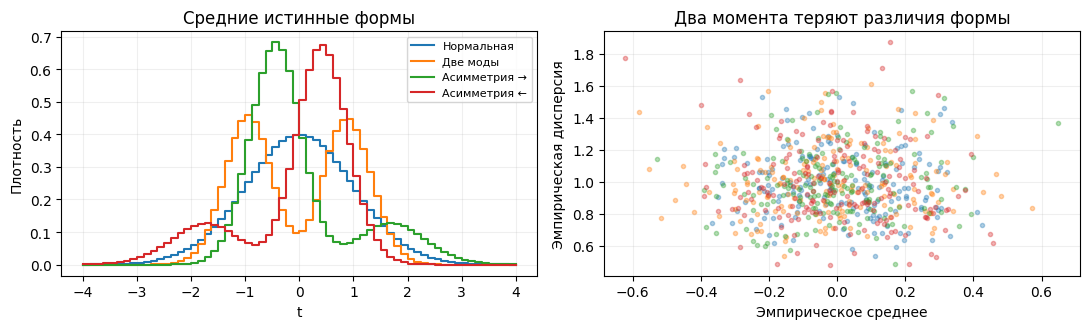

In [18]:
audit_truth, audit_true_masses = simulation_audit()
audit_rows = []
for name, result in methods.items():
    pred = result['test_labels']
    audit_rows.append([name, adjusted_rand_score(audit_truth[test_ids], pred),
                       normalized_mutual_info_score(audit_truth[test_ids], pred)])
table(['Метод', 'Test ARI', 'Test NMI'], audit_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for k, label in enumerate(['Нормальная', 'Две моды', 'Асимметрия →', 'Асимметрия ←']):
    plot_histogram(axes[0], audit_true_masses[audit_truth == k].mean(0)/widths, edges, label=label)
    pts = histogram_moments(P, centers)[audit_truth == k]
    axes[1].scatter(*pts.T, s=9, alpha=.35, label=label)
axes[0].set(xlabel='t', ylabel='Плотность', title='Средние истинные формы')
axes[0].legend(fontsize=8)
axes[1].set(xlabel='Эмпирическое среднее', ylabel='Эмпирическая дисперсия',
            title='Два момента теряют различия формы')
plt.tight_layout(); plt.show()


### Контрольный эксперимент: меньше отсчётов на объект

Чтобы сравнить модели на более шумных гистограммах, уменьшим каждый объект
до 30 отсчётов, выбирая их **без возвращения из уже имеющихся счётчиков**.
Обучение и тест сохраняют раздельность; параметры моделей не подбираются.
Изначально все $n_i\geq60$, поэтому операция корректна. Здесь меняется
точность оценки формы, а не число объектов. Этот контроль задан заранее;
его результаты тоже нельзя использовать для повторной настройки по меткам.


In [19]:
def thin_histograms(C, n_keep=30, seed=94):
    rng = np.random.default_rng(seed)
    result = []
    for counts in C:
        # Эквивалент многомерного гипергеометрического прореживания.
        draws = np.repeat(np.arange(C.shape[1]), counts)
        selected = rng.choice(draws, size=n_keep, replace=False)
        result.append(np.bincount(selected, minlength=C.shape[1]))
    return np.array(result)

C_low = thin_histograms(C)
P_low = C_low/C_low.sum(1, keepdims=True)
low_methods = {'Среднее + дисперсия': fit_moment_baseline(P_low[train_ids], P_low[test_ids])}
if ready('Метод для распределений'):
    low_methods['Предложенный GMM'] = fit_distribution_clustering(
        P_low[train_ids], P_low[test_ids], K, 12)
if ready('Мультиномиальная смесь'):
    low_model = fit_multinomial(C_low[train_ids], K, seed=8)
    low_methods['EM: мультиномиальная смесь'] = dict(
        test_labels=predict_multinomial(low_model, C_low[test_ids]).argmax(1))
table(['Метод', 'Test ARI, n_i=30', 'Test NMI, n_i=30'], [
    [name, adjusted_rand_score(audit_truth[test_ids], r['test_labels']),
     normalized_mutual_info_score(audit_truth[test_ids], r['test_labels'])]
    for name, r in low_methods.items()])


| Метод | Test ARI, n_i=30 | Test NMI, n_i=30 |
| --- | --- | --- |
| Среднее + дисперсия | -0.0033 | 0.0120 |
| Предложенный GMM | 0.6991 | 0.6802 |
| EM: мультиномиальная смесь | 0.8226 | 0.7773 |

**Обсудите результаты.** Насколько изменились методы при уменьшении $n_i$?
Что объясняется потерей информации, а что — неверным предположением об одной
фиксированной форме внутри кластера? Почему один удачный seed не доказывает
преимущество метода на всех распределениях? Не сравнивайте численные
значения log likelihood GMM в разных признаках или с мультиномиальной
моделью: это плотности/вероятности разных наблюдений и разных мер.


**Разбор контрольного запуска.** Два момента почти не различают семейства,
поскольку задача специально сохраняет их теоретические значения. Четыре
момента и sqrt/PCA сохраняют различия формы и хорошо работают при исходных
размерах выборок. В данном запуске при $n_i=30$ качество sqrt/PCA/GMM заметно
снижается, а мультиномиальная смесь сохраняет больше информации о группах.
Это результат заданного генератора и эксперимента, а не универсальное
ранжирование методов. Стабильность трёх стартов не устраняет ошибку модели.

Мультиномиальные шаблоны усредняют форму внутри группы и не описывают
индивидуальные сдвиги. Транспортный метод ниже учитывает физическое
расстояние по оси, поэтому может делить группы по положению массы, даже
когда желаемые классы определены формой. Для другой постановки это свойство
может оказаться преимуществом. VAE в приложении — ещё один способ построить
представление, но его сложность не даёт автоматического выигрыша.


## Приложение A. Транспортное расстояние и медоиды

Для дискретных мер на общих упорядоченных центрах $t_1<\cdots<t_B$ точно
$$W_1(p,q)=\sum_{b=1}^{B-1}|F_p(t_b)-F_q(t_b)|(t_{b+1}-t_b),
\qquad F_p(t_b)=\sum_{j\leq b}p_j.$$
Формула относится к массам в **центрах** бинов. Для непрерывных кусочно
постоянных плотностей интеграл CDF внутри бинов вычисляется иначе.

Здесь сдвинуть массу в соседний бин дешевле, чем перенести её на другой конец
оси. K-means напрямую с произвольным расстоянием не работает: среднее
минимизирует сумму квадратов евклидовых расстояний. Вместо него используем
медоиды — представители выбираются из обучающих объектов, обновление
минимизирует сумму расстояний внутри группы. Это локальная оптимизация.

**Самостоятельно:** реализуйте `wasserstein_matrix` и `fit_w1_medoids`.
На каждом шаге назначьте ближайший медоид и выберите внутри каждой группы
объект с минимальной суммой расстояний. Сделайте несколько стартов.
Оцените сложность хранения $O(N^2)$ и чувствительность к сдвигу.


In [20]:
def wasserstein_matrix(P1, P2, centers):
    A = np.cumsum(P1, axis=1)[:, :-1] * np.diff(centers)
    B = np.cumsum(P2, axis=1)[:, :-1] * np.diff(centers)
    return cdist(A, B, metric='cityblock')

def fit_w1_medoids(P_fit, P_new, K, centers, seed=8, n_init=6):
    rng = np.random.default_rng(seed)
    D = wasserstein_matrix(P_fit, P_fit, centers)
    best = None
    for _ in range(n_init):
        ids = [int(rng.integers(len(P_fit)))]
        while len(ids) < K:
            distance = D[:, ids].min(1)
            if distance.sum() == 0:
                raise ValueError('Недостаточно различных объектов для K медоидов.')
            ids.append(int(rng.choice(len(P_fit), p=distance/distance.sum())))
        ids = np.array(ids)
        for step in range(50):
            labels = D[:, ids].argmin(1)
            new = ids.copy()
            for k in range(K):
                members = np.flatnonzero(labels == k)
                if len(members):
                    new[k] = members[D[np.ix_(members, members)].sum(1).argmin()]
            if np.array_equal(new, ids):
                break
            ids = new
        cost = D[:, ids].min(1).sum()
        if best is None or cost < best[0]:
            best = cost, ids
    cost, ids = best
    return dict(train_labels=D[:, ids].argmin(1),
                test_labels=wasserstein_matrix(P_new, P_fit[ids], centers).argmin(1),
                medoid_ids=ids, cost=cost)


Транспорт: проверки пройдены.


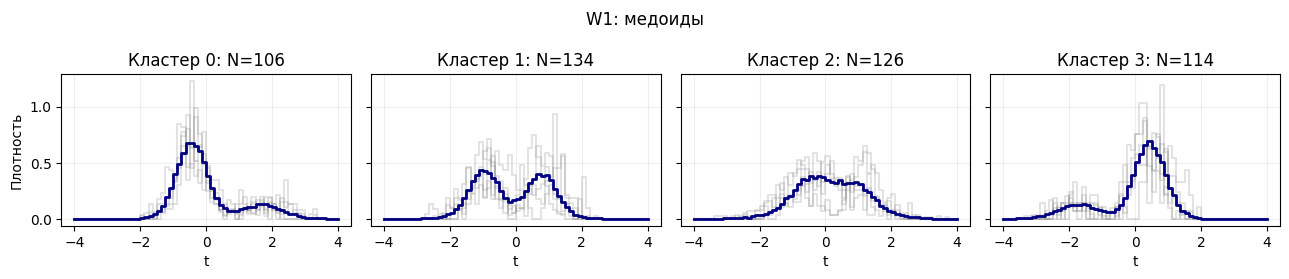

| Метод | Test ARI | Test NMI |
| --- | --- | --- |
| W1: медоиды | 0.7696 | 0.7669 |

In [21]:
def test_transport():
    from scipy.stats import wasserstein_distance
    P0 = np.eye(3)
    grid = np.array([-2., 0., 3.])
    D = wasserstein_matrix(P0, P0, grid)
    np.testing.assert_allclose(D, np.abs(grid[:, None]-grid[None, :]))
    p, q = np.array([.3, .2, .5]), np.array([.1, .7, .2])
    np.testing.assert_allclose(wasserstein_matrix(p[None], q[None], grid)[0, 0],
                               wasserstein_distance(grid, grid, p, q))
    result = fit_w1_medoids(P_train[:80], P_test[:9], K, centers, n_init=2)
    assert result['test_labels'].shape == (9,)
    assert len(np.unique(result['medoid_ids'])) == K

check('Транспорт', test_transport)
if ready('Транспорт'):
    transport = fit_w1_medoids(P_train, P_test, K, centers)
    plot_clusters(P_train, transport['train_labels'], 'W1: медоиды')
    table(['Метод', 'Test ARI', 'Test NMI'], [
        ['W1: медоиды', adjusted_rand_score(audit_truth[test_ids], transport['test_labels']),
         normalized_mutual_info_score(audit_truth[test_ids], transport['test_labels'])]])


## Приложение B. Если число кластеров неизвестно

В основной задаче $K=4$ задано. Для другой задачи можно сравнивать $K$ по
внутренней валидации, BIC, устойчивости и смыслу групп. Пример ниже фиксирует
**одно** пространство sqrt-масс → PCA(8), обучает его только на training
и сравнивает GMM в нём:
$$\mathrm{BIC}=-2\ell(\widehat\theta)+m\log N,\qquad
m=(K-1)+Kd+K d(d+1)/2$$
для полной ковариации. Меньше — лучше. Обычный вывод BIC опирается на
регулярные асимптотические предположения; смеси имеют особые точки, поэтому
здесь это практический ориентир. Число компонент, лучше описывающее плотность,
может отличаться от числа содержательных семейств. Не выбирайте по тестовому ARI.


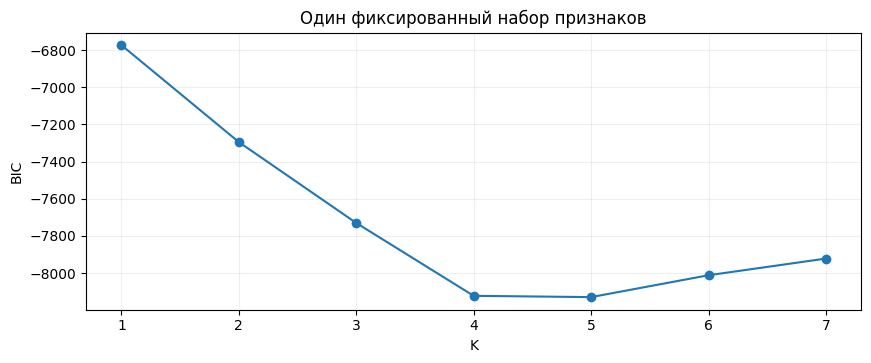

In [22]:
bic_pca = PCA(8, svd_solver='full').fit(np.sqrt(P_train))
Z_bic = bic_pca.transform(np.sqrt(P_train))
bic_values = []
for k in range(1, 8):
    model = GaussianMixture(k, covariance_type='full', reg_covar=1e-4,
                            n_init=4, random_state=71).fit(Z_bic)
    bic_values.append(model.bic(Z_bic))
plt.plot(range(1, 8), bic_values, marker='o')
plt.xlabel('K'); plt.ylabel('BIC'); plt.title('Один фиксированный набор признаков')
plt.show()


## Приложение C. Связь с прошлым семинаром: VAE → GMM

Вместо линейного PCA можно обучить представление без меток. Возьмём
$$z_i\sim\mathcal N(0,I),\quad
c_i\mid z_i,n_i\sim\operatorname{Multinomial}
 (n_i,\operatorname{softmax}(g_\theta(z_i))),$$
$$q_\phi(z_i\mid c_i,n_i)=\mathcal N(\mu_\phi,\operatorname{diag}(e^{s_\phi})).$$
Энкодер получает $\sqrt{p_i}$ и $\log n_i$; скейлер последнего обучается
только на обучающих объектах. Используем обычный ELBO с коэффициентом KL, равным 1:
$$-\mathcal L_i=-\sum_b c_{ib}\mathbb E_q\log\rho_{\theta b}(z_i)
+\frac12\sum_j(\mu_{ij}^2+e^{s_{ij}}-1-s_{ij})+\text{const}(c_i).$$
Мультиномиальный коэффициент не влияет на градиенты, но нужен для абсолютного
log probability. В обучении его опускаем. Деление реконструкции на $n_i$
изменило бы соотношение с KL и перестало бы быть этим ELBO.
Бинарная cross-entropy для долей в бинах не соответствует выбранной модели.

После обучения зафиксируйте энкодер, возьмите **средние** $\mu_\phi$ и обучите
GMM на обучающих представлениях. Это двухэтапная эвристика, а не совместная
модель кластеров и не гарантия кластеризуемости латентного пространства.
Непрерывная нормальная априорная плотность VAE сама не задаёт $K$ кластеров.

Код предоставлен как дополнительный эксперимент; включите `RUN_VAE = True`.
Все параметры и число эпох зафиксированы заранее; тест не выбирает чекпойнт.


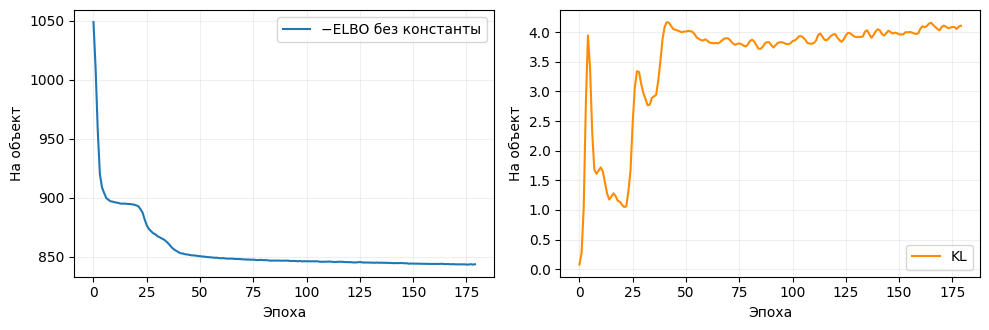

| Метод | Test ARI | Test NMI |
| --- | --- | --- |
| VAE(3) → GMM | 0.9467 | 0.9377 |

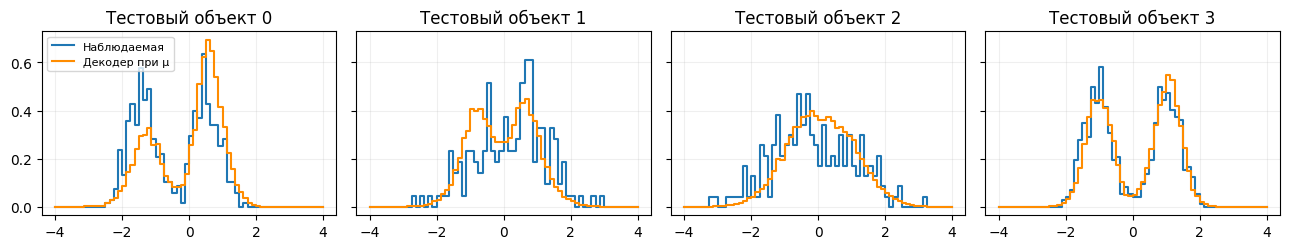

PyTorch 2.4.1+cu121 | устройство CPU | 180 эпох, latent_dim=3


In [23]:
if RUN_VAE:
    import torch
    from torch import nn
    import torch.nn.functional as F
    torch.manual_seed(81)
    torch.set_num_threads(2)
    logn_mean = np.log(C_train.sum(1)).mean()
    logn_scale = np.log(C_train.sum(1)).std()

    def encoder_input(C):
        P = C/C.sum(1, keepdims=True)
        logn = (np.log(C.sum(1))-logn_mean)/logn_scale
        return torch.tensor(np.c_[np.sqrt(P), logn], dtype=torch.float32)

    class HistogramVAE(nn.Module):
        def __init__(self, B, latent=3):
            super().__init__()
            self.encoder = nn.Sequential(nn.Linear(B+1, 48), nn.Tanh(), nn.Linear(48, 32), nn.Tanh())
            self.mu = nn.Linear(32, latent)
            self.logvar = nn.Linear(32, latent)
            self.decoder = nn.Sequential(nn.Linear(latent, 32), nn.Tanh(), nn.Linear(32, 48),
                                         nn.Tanh(), nn.Linear(48, B))

        def encode(self, x):
            h = self.encoder(x)
            return self.mu(h), self.logvar(h).clamp(-8, 8)

        def loss(self, inputs, counts):
            mu, logv = self.encode(inputs)
            z = mu + torch.exp(.5*logv)*torch.randn_like(mu)
            reconstruction = -(counts*F.log_softmax(self.decoder(z), dim=1)).sum(1)
            kl = .5*(mu.square()+logv.exp()-1-logv).sum(1)
            return (reconstruction+kl).mean(), reconstruction.mean(), kl.mean()

    vae = HistogramVAE(C.shape[1])  # CPU: одинаковое устройство модели и данных.
    inputs = encoder_input(C_train)
    counts = torch.tensor(C_train, dtype=torch.float32)
    optimizer = torch.optim.Adam(vae.parameters(), lr=2e-3)
    vae_history = []
    generator = torch.Generator().manual_seed(82)
    for epoch in range(180):
        totals = np.zeros(3)
        for batch in torch.randperm(len(counts), generator=generator).split(80):
            optimizer.zero_grad()
            loss, recon, kl = vae.loss(inputs[batch], counts[batch])
            loss.backward(); optimizer.step()
            totals += len(batch)*np.array([loss.item(), recon.item(), kl.item()])
        vae_history.append(totals/len(counts))
    vae.eval()
    with torch.no_grad():
        latent_train = vae.encode(inputs)[0].numpy()
        latent_test = vae.encode(encoder_input(C_test))[0].numpy()
        recon_P = vae.decoder(torch.tensor(latent_test[:4])).softmax(1).numpy()
    np.testing.assert_allclose(recon_P.sum(1), 1., atol=1e-6)
    vae_gmm = GaussianMixture(K, covariance_type='full', n_init=6,
                             reg_covar=1e-4, random_state=83).fit(latent_train)
    vae_labels = vae_gmm.predict(latent_test)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    axes[0].plot(np.array(vae_history)[:, 0], label='−ELBO без константы')
    axes[0].set(xlabel='Эпоха', ylabel='На объект'); axes[0].legend()
    axes[1].plot(np.array(vae_history)[:, 2], color='darkorange', label='KL')
    axes[1].set(xlabel='Эпоха', ylabel='На объект'); axes[1].legend()
    plt.tight_layout(); plt.show()
    table(['Метод', 'Test ARI', 'Test NMI'], [[
        'VAE(3) → GMM', adjusted_rand_score(audit_truth[test_ids], vae_labels),
        normalized_mutual_info_score(audit_truth[test_ids], vae_labels)]])
    fig, axes = plt.subplots(1, 4, figsize=(13, 2.6), sharey=True)
    for j, ax in enumerate(axes):
        plot_histogram(ax, P_test[j]/widths, edges, label='Наблюдаемая')
        plot_histogram(ax, recon_P[j]/widths, edges, label='Декодер при μ', color='darkorange')
        ax.set_title(f'Тестовый объект {j}')
    axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()
    print('PyTorch', torch.__version__, '| устройство CPU | 180 эпох, latent_dim=3')
else:
    print('VAE — необязательное приложение; RUN_VAE = False.')


**Вопросы к VAE.** Декодер при $\mu_\phi$ — это не интеграл по
$q_\phi(z\mid c)$ и не новая случайная гистограмма. Почему хорошая реконструкция
не гарантирует хорошие кластеры? Не закодировал ли энкодер прежде всего $n_i$?
Какие изменения понадобятся, чтобы дискретная компонента вошла в саму
генеративную модель? При небольшом числе объектов PCA часто оказывается
достаточным и более прозрачным вариантом.

## Что сдать

Реализации E- и M-шагов и цикла EM с пройденными проверками; игрушечные
эксперименты с объяснением мягких назначений и ковариаций; минимум два
осмысленных метода кластеризации распределений; изображения представителей,
устойчивость, контроль с меньшими $n_i$ и итоговый аудит после фиксации параметров.
В выводе объясните смысл объектов, выбранную геометрию и ограничения модели.

**Вопросы для самопроверки:** почему EM не убывает? где возникает KL?
когда GMM вырождается? что даёт несколько стартов? чем массы отличаются
от плотностей? когда счётчики лучше нормированных долей? что теряется в
двух моментах? в каких пространствах допустимо сравнивать log likelihood?


## Источники

1. A. P. Dempster, N. M. Laird, D. B. Rubin (1977).
   *Maximum Likelihood from Incomplete Data via the EM Algorithm*.
   [DOI: 10.1111/j.2517-6161.1977.tb01600.x](https://doi.org/10.1111/j.2517-6161.1977.tb01600.x).
2. R. M. Neal, G. E. Hinton (1998). *A View of the EM Algorithm that Justifies
   Incremental, Sparse, and Other Variants*.
   [Авторская страница](https://www.cs.toronto.edu/~hinton/absps/emk.pdf).
3. scikit-learn. [Gaussian mixture models](https://scikit-learn.org/stable/modules/mixture.html),
   [GaussianMixture](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html).
4. SciPy. [wasserstein_distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html).
5. D. P. Kingma, M. Welling. *Auto-Encoding Variational Bayes*.
   [arXiv:1312.6114](https://arxiv.org/abs/1312.6114).

Генератор гистограмм, контрольные опыты и VAE для счётчиков — учебные
конструкции этого семинара; они не воспроизводят результаты указанных статей.
